# 05 · Game tracking (sample)

Files: `game_tracking_{2023,2024,2025}.csv` — 0.3–1.0 GB each. Uses a **5% game-level sample** per season cached to `eda/cache/` (see `utils.sample_tracking`).

**Questions:** Schema/cadence/quality of the tracking; how it joins to `player_play`; what the full-data size/strategy implies.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from utils import *
set_style()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

In [2]:
import time
frames = {}
for s in (2023, 2024, 2025):
    t = time.time(); frames[s] = sample_tracking(s, frac_games=0.05); print(s, frames[s].shape, f"{time.time()-t:.1f}s")
gt = pd.concat([f.assign(season_file=s) for s, f in frames.items()], ignore_index=True)
gt["time"] = pd.to_datetime(gt.time)
gt.head()

2023 (223265, 12) 4.0s


2024 (298590, 12) 0.6s


2025 (546029, 12) 0.9s


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event,season_file
0,2023082751,746,56066,2023-08-28 00:38:28.800,93.73,29.64,0.0,0.0,0.0,254.1,238.63,NaN,2023
1,2023082751,746,56066,2023-08-28 00:38:28.900,93.73,29.64,0.0,0.0,0.0,254.1,244.29,NaN,2023
2,2023082751,746,56066,2023-08-28 00:38:29.000,93.73,29.64,0.0,0.0,0.0,254.1,243.53,NaN,2023
3,2023082751,746,56066,2023-08-28 00:38:29.100,93.73,29.64,0.0,0.0,0.0,254.1,241.31,NaN,2023
4,2023082751,746,56066,2023-08-28 00:38:29.200,93.73,29.64,0.0,0.0,0.0,254.1,243.44,NaN,2023


In [3]:
print("games sampled:", gt.groupby("season_file").game_id.nunique().to_dict())
print("memory MB:", round(gt.memory_usage(deep=True).sum()/1e6, 1))
missingness(gt)

games sampled: {2023: 22, 2024: 13, 2025: 17}
memory MB: 112.0


,n_missing,pct_missing,dtype
event,997477,93.41,str
game_id,0,0.00,int64
play_id,0,0.00,int64
nfl_id,0,0.00,int64
time,0,0.00,datetime64[us]
x,0,0.00,float64
y,0,0.00,float64
s,0,0.00,float64
a,0,0.00,float64
dis,0,0.00,float64


## Structure: rows per play, players per play, frame cadence

In [4]:
gt = gt.sort_values(["game_id","play_id","nfl_id","time"])
gt["gap"] = gt.groupby(["game_id","play_id","nfl_id"]).time.diff().dt.total_seconds()
print(gt.gap.round(2).value_counts().head(6))
per = gt.groupby(["game_id","play_id","nfl_id"]).size()
print("frames per (play, player):"); print(per.describe())
print("tracked players per play:"); print(gt.groupby(["game_id","play_id"]).nfl_id.nunique().describe())

gap
0.1    1053124
Name: count, dtype: int64
frames per (play, player):
count    14760.000000
mean        72.349864
std         16.613430
min         17.000000
25%         61.000000
50%         70.000000
75%         81.000000
max        176.000000
dtype: float64
tracked players per play:
count    5735.000000
mean        2.573670
std         1.555654
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: nfl_id, dtype: float64


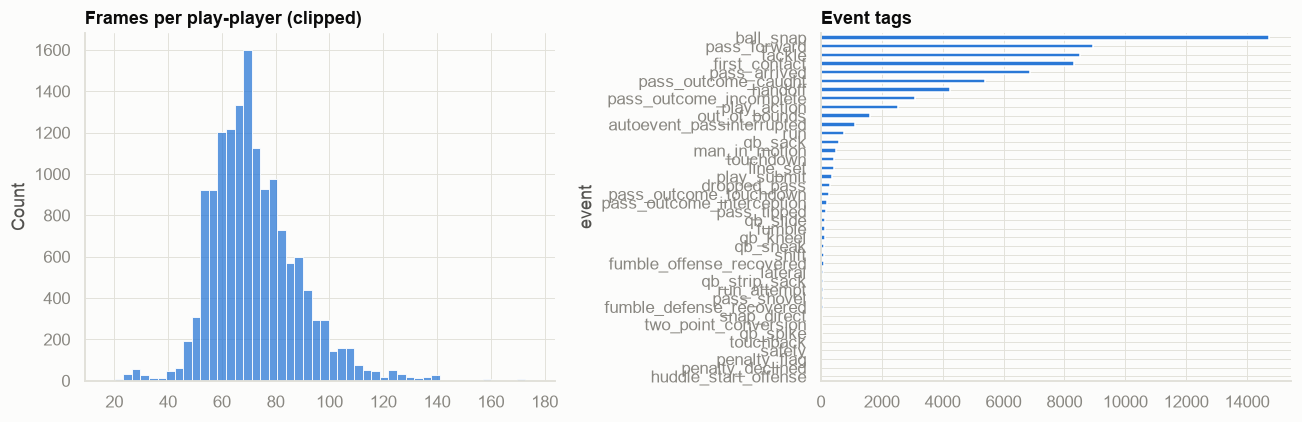

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per.clip(upper=200), bins=50, color=PALETTE[0], ax=axes[0]); axes[0].set_title("Frames per play-player (clipped)")
gt.event.value_counts().plot.barh(color=PALETTE[0], ax=axes[1]).invert_yaxis(); axes[1].set_title("Event tags")
plt.tight_layout(); savefig(fig, "05_structure")

In [6]:
gt["month"] = gt.time.dt.to_period("M")
print(pd.crosstab(gt.month, gt.season_file))

season_file   2023    2024    2025
month                             
2023-08      45277       0       0
2023-09      23126       0       0
2023-10       5651       0       0
2023-11      34590       0       0
2023-12      77635       0       0
2024-01      30863       0       0
2024-02       6123       0       0
2024-08          0   33992       0
2024-09          0   64671       0
2024-10          0   16685       0
2024-11          0   56509       0
2024-12          0  105706       0
2025-01          0   21027       0
2025-08          0       0   61660
2025-09          0       0   99568
2025-10          0       0  185084
2025-11          0       0  176804
2025-12          0       0   22913


Season files can contain Jan–Feb timestamps of the following calendar year (late-season/playoff games); the file label is the NFL season.

## Kinematics & quality

         count        mean         std   min     0.1%      50%   99.9%     max
x    1067884.0   60.291393   24.430906 -5.17  2.51883   60.180  117.46  125.04
y    1067884.0   26.754301    9.619210 -7.69 -1.15000   26.785   54.62   60.96
s    1067884.0    2.573601    2.121007  0.00  0.00000    2.140    9.38   10.35
a    1067884.0    1.621083    1.241497  0.00  0.00000    1.400    6.62   11.88
dis  1067884.0    0.261220    0.213243  0.00  0.00000    0.220    0.94    2.58
o    1067884.0  178.202032  100.981359  0.00  0.45000  176.370  359.52  360.00
dir  1067884.0  180.752638  103.470808  0.00  0.33000  180.730  359.67  360.00
out of bounds share: 0.004258889542309839


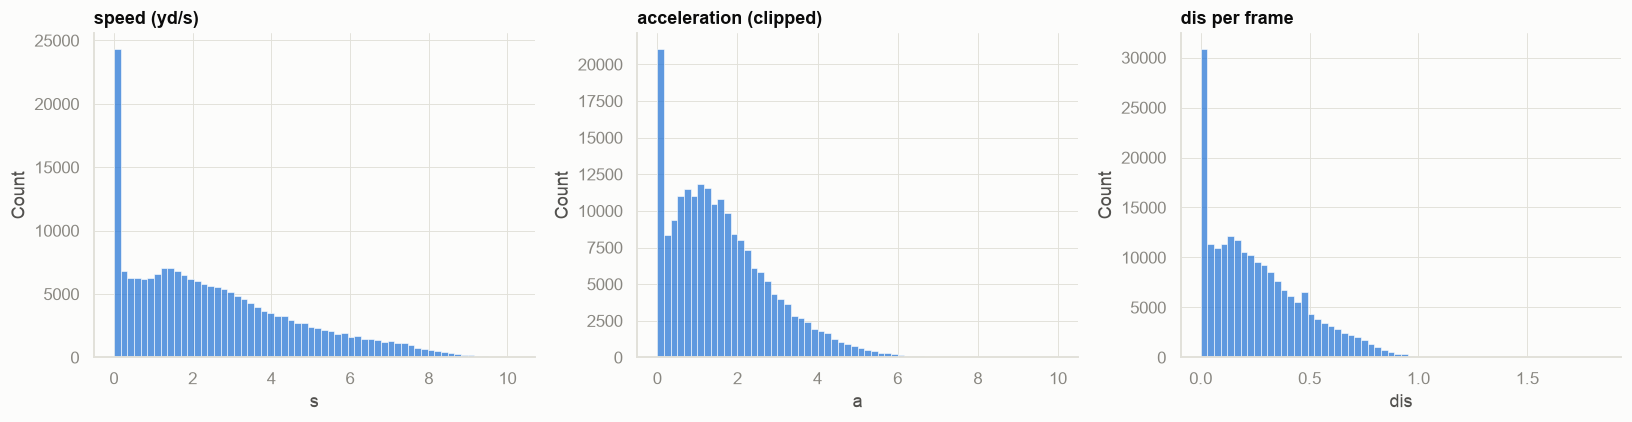

In [7]:
print(gt[["x","y","s","a","dis","o","dir"]].describe(percentiles=[.001,.5,.999]).T)
print("out of bounds share:", ((gt.x < 0) | (gt.x > 120) | (gt.y < 0) | (gt.y > 53.34)).mean())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(gt.s.sample(200000, random_state=0), bins=60, color=PALETTE[0], ax=axes[0]).set_title("speed (yd/s)")
sns.histplot(gt.a.clip(-10, 10).sample(200000, random_state=0), bins=60, color=PALETTE[0], ax=axes[1]).set_title("acceleration (clipped)")
sns.histplot(gt.dis.sample(200000, random_state=0), bins=60, color=PALETTE[0], ax=axes[2]).set_title("dis per frame")
plt.tight_layout(); savefig(fig, "05_kinematics")

## Speed by position (join to players & player_play)

In [8]:
players = load_csv("players")[["nfl_id","nfl_position"]]
pp = load_csv("player_play", usecols=["game_id","play_id","nfl_id","lined_up_position"])
keys = gt[["game_id","play_id","nfl_id"]].drop_duplicates()
m = keys.merge(pp, on=["game_id","play_id","nfl_id"], how="left", indicator=True)
print("tracking (play,player) found in player_play:", (m._merge == "both").mean())
print("tracking nfl_ids in players.csv:", keys.nfl_id.isin(players.nfl_id).mean())

tracking (play,player) found in player_play: 0.9902439024390244
tracking nfl_ids in players.csv: 1.0


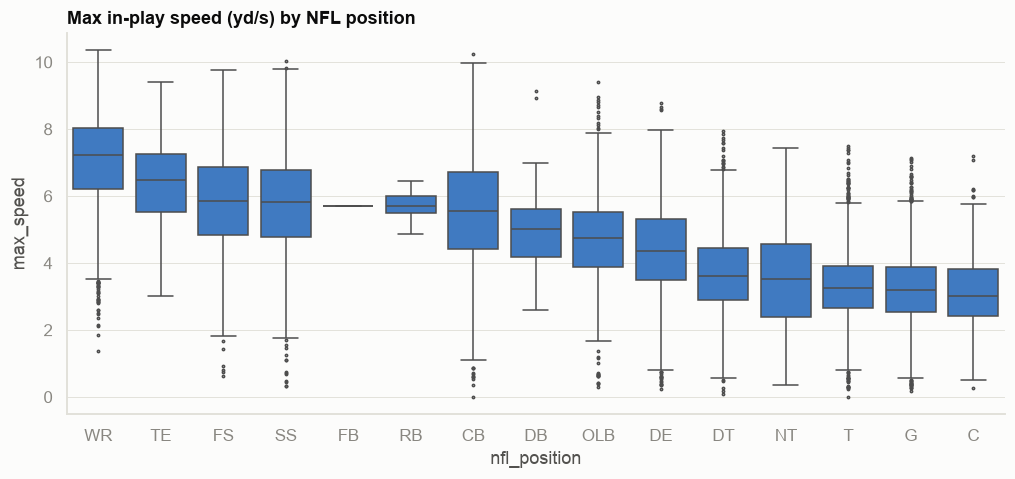

In [9]:
top = gt.merge(players, on="nfl_id").groupby(["game_id","play_id","nfl_id","nfl_position"]).s.max().rename("max_speed").reset_index()
order = top.groupby("nfl_position").max_speed.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=top, x="nfl_position", y="max_speed", order=order, color=PALETTE[0], fliersize=1.5, linewidth=1, ax=ax); ax.set_title("Max in-play speed (yd/s) by NFL position")
savefig(fig, "05_speed_by_pos")

## Sample of one play

Text(0.0, 1.0, 'Tracked rookies on game 2023082654 play 96')

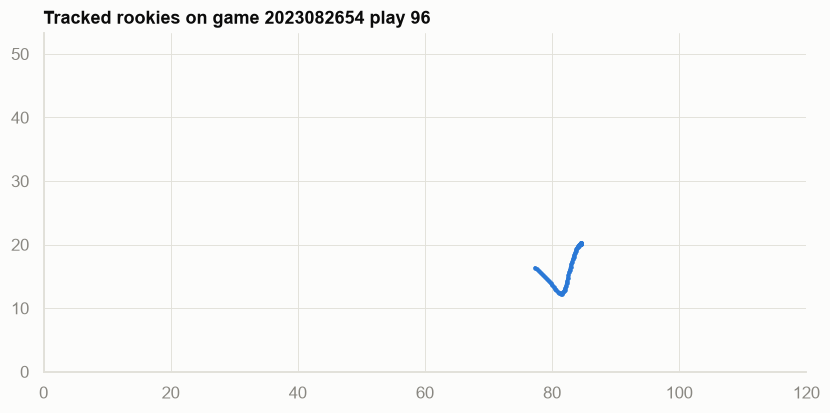

In [10]:
g, p = gt[gt.event == "ball_snap"][["game_id","play_id"]].iloc[0]
play = gt[(gt.game_id == g) & (gt.play_id == p)]
fig, ax = plt.subplots(figsize=(9, 4))
for i, (nid, e) in enumerate(play.groupby("nfl_id")): ax.plot(e.x, e.y, color=PALETTE[i % 8], lw=2, marker="o", ms=2)
ax.set_xlim(0, 120); ax.set_ylim(0, 53.3); ax.set_aspect("equal"); ax.set_title(f"Tracked rookies on game {g} play {p}")

## Scale & full-data strategy
Sizes on disk: 2023 ≈ 0.34 GB, 2024 ≈ 0.72 GB, 2025 ≈ 1.02 GB (≈2.1 GB). Use the row counts below (extrapolated from the 5% sample) to decide among DuckDB-on-CSV, Parquet conversion, or polars.

In [11]:
import os
rows = []
for s in (2023, 2024, 2025):
    size = os.path.getsize(RAW / f"game_tracking_{s}.csv") / 1e9
    rows.append({"season": s, "csv_GB": round(size, 2), "sample_rows": len(frames[s]), "est_total_rows_M": round(len(frames[s]) / 0.05 / 1e6, 1),
                 "est_in_memory_GB": round(frames[s].memory_usage(deep=True).sum() / 0.05 / 1e9, 1)})
pd.DataFrame(rows)

,season,csv_GB,sample_rows,est_total_rows_M,est_in_memory_GB
0,2023,0.34,223265,4.5,0.4
1,2024,0.72,298590,6.0,0.6
2,2025,1.02,546029,10.9,1.1


## Findings / follow-ups
- Fill in after reviewing outputs.